<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/susy_field_theory/susyft_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Field Theory* — `susyft_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYFT CH04 Figures
**Supersymmetric Gauge Theories**

In [1]:

import numpy as np, matplotlib.pyplot as plt, os
BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
GOLD='#e8b84b';BLUE='#7ec8e3';PURP='#c792ea'
GREEN='#90ee90';RED='#e07070';ORAN='#e8a838';TEAL='#2ec4b6'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,'axes.edgecolor':EDGE,
    'grid.color':EDGE,'grid.alpha':0.3,'font.size':12,'axes.titlesize':13,
    'axes.titleweight':'bold','axes.titlecolor':GOLD,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110})
OUTDIR='figures/ch04'; os.makedirs(OUTDIR,exist_ok=True)
def save(name,fig=None):
    f=fig or plt.gcf()
    p=f'{OUTDIR}/{name}'; f.savefig(p,dpi=180,bbox_inches='tight',facecolor=BG)
    print(f'saved->{p}'); plt.show()
print('Setup ch04')


Setup ch04


saved->figures/ch04/fig01_vector_sqcd.png


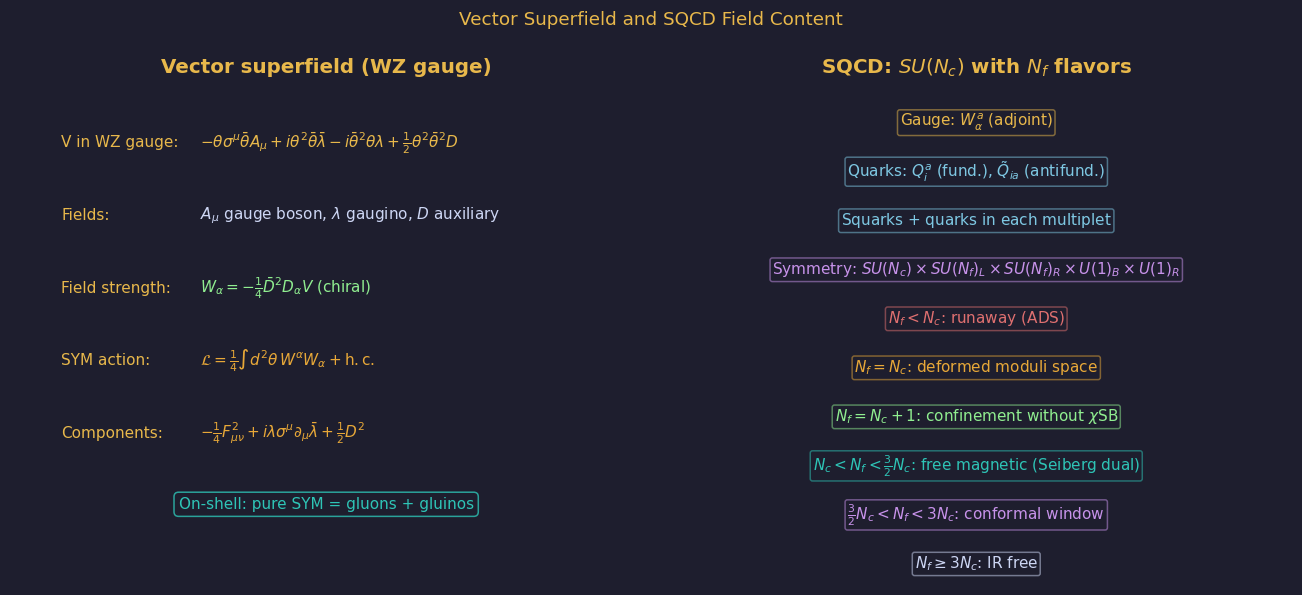

In [2]:

fig,axes=plt.subplots(1,2,figsize=(12,5.5))
fig.suptitle('Vector Superfield and SQCD Field Content',color=GOLD,fontsize=12)
ax=axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Vector superfield (WZ gauge)',color=GOLD)
rows=[
  ('V in WZ gauge:', r'$-\theta\sigma^\mu\bar\theta A_\mu + i\theta^2\bar\theta\bar\lambda - i\bar\theta^2\theta\lambda + \frac{1}{2}\theta^2\bar\theta^2 D$', GOLD),
  ('Fields:',        r'$A_\mu$ gauge boson, $\lambda$ gaugino, $D$ auxiliary', FG),
  ('Field strength:',r'$W_\alpha = -\frac{1}{4}\bar D^2 D_\alpha V$ (chiral)', GREEN),
  ('SYM action:',    r'$\mathcal{L} = \frac{1}{4}\int d^2\theta\,W^\alpha W_\alpha + \mathrm{h.c.}$', ORAN),
  ('Components:',    r'$-\frac{1}{4}F_{\mu\nu}^2 + i\lambda\sigma^\mu\partial_\mu\bar\lambda + \frac{1}{2}D^2$', ORAN),
]
ys=np.linspace(0.88,0.30,len(rows))
for (label,val,col),y in zip(rows,ys):
    ax.text(0.08,y,label,ha='left',va='center',fontsize=10,color=GOLD,transform=ax.transAxes)
    ax.text(0.30,y,val,ha='left',va='center',fontsize=10,color=col,transform=ax.transAxes)
ax.text(0.5,0.15,'On-shell: pure SYM = gluons + gluinos',ha='center',fontsize=10,
        color=TEAL,transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=TEAL,alpha=0.8))

ax2=axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r'SQCD: $SU(N_c)$ with $N_f$ flavors',color=GOLD)
sqcd=[
  (r'Gauge: $W_\alpha^a$ (adjoint)',GOLD),
  (r'Quarks: $Q_i^a$ (fund.), $\tilde Q_{ia}$ (antifund.)',BLUE),
  (r'Squarks $+$ quarks in each multiplet',BLUE),
  (r'Symmetry: $SU(N_c)\times SU(N_f)_L\times SU(N_f)_R\times U(1)_B\times U(1)_R$',PURP),
  (r'$N_f < N_c$: runaway (ADS)', RED),
  (r'$N_f = N_c$: deformed moduli space', ORAN),
  (r'$N_f = N_c+1$: confinement without $\chi$SB', GREEN),
  (r'$N_c < N_f < \frac{3}{2}N_c$: free magnetic (Seiberg dual)', TEAL),
  (r'$\frac{3}{2}N_c < N_f < 3N_c$: conformal window', PURP),
  (r'$N_f \geq 3N_c$: IR free', FG),
]
ys2=np.linspace(0.92,0.04,len(sqcd))
for (txt,col),y in zip(sqcd,ys2):
    ax2.text(0.5,y,txt,ha='center',va='center',fontsize=10,color=col,
             transform=ax2.transAxes,bbox=dict(boxstyle='round,pad=0.15',fc=BG,ec=col,alpha=0.5))
plt.tight_layout()
save('fig01_vector_sqcd.png',fig)


saved->figures/ch04/fig02_sqed_moduli.png


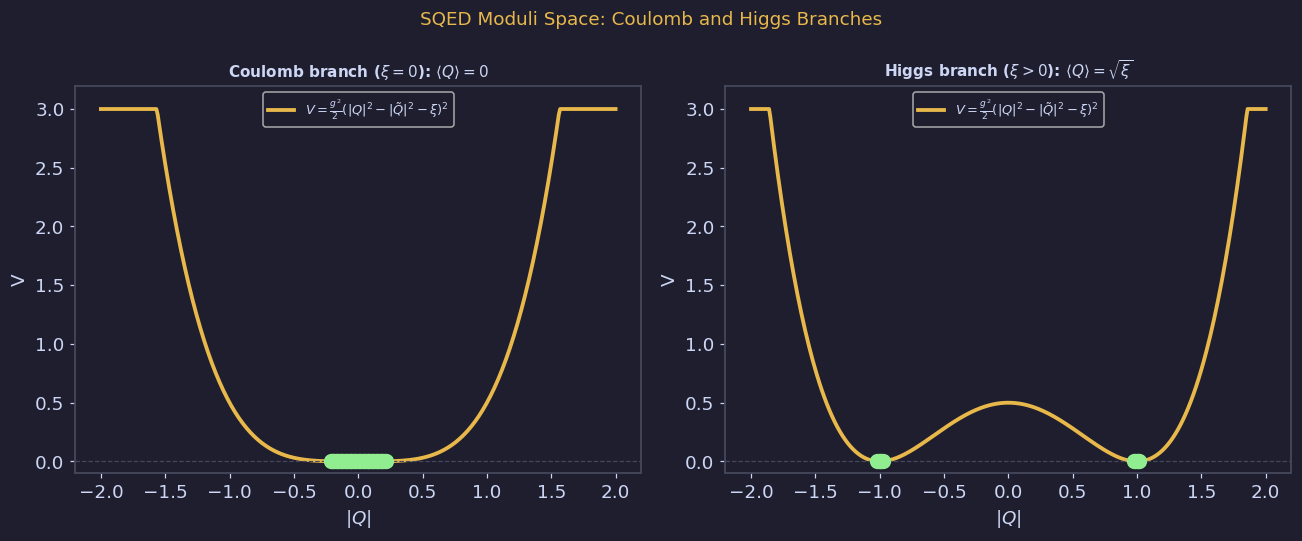

In [3]:

fig,axes=plt.subplots(1,2,figsize=(12,5))
fig.suptitle('SQED Moduli Space: Coulomb and Higgs Branches',color=GOLD,fontsize=12)
phi=np.linspace(-2,2,400)
for ax_,xi_,title_,col_ in [
    (axes[0],0,'Coulomb branch ($\\xi=0$): $\\langle Q\\rangle=0$',TEAL),
    (axes[1],1,'Higgs branch ($\\xi>0$): $\\langle Q\\rangle=\\sqrt{\\xi}$',BLUE),
]:
    V=(phi**2-xi_)**2*0.5
    ax_.set_facecolor(BG)
    ax_.plot(phi,np.clip(V,0,3),color=GOLD,lw=2.5,label=r'$V=\frac{g^2}{2}(|Q|^2-|\tilde Q|^2-\xi)^2$')
    ax_.axhline(0,color=EDGE,lw=0.8,ls='--')
    mins = np.where(np.abs(phi**2-xi_)<0.05)[0]
    if len(mins): ax_.plot(phi[mins],V[mins],'o',color=GREEN,ms=9,zorder=6)
    ax_.set_title(title_,color=FG,fontsize=10)
    ax_.set_xlabel(r'$|Q|$'); ax_.set_ylabel('V')
    ax_.legend(fontsize=8.5); ax_.set_ylim(-0.1,3.2)
plt.tight_layout()
save('fig02_sqed_moduli.png',fig)


saved->figures/ch04/fig03_n2_n4.png


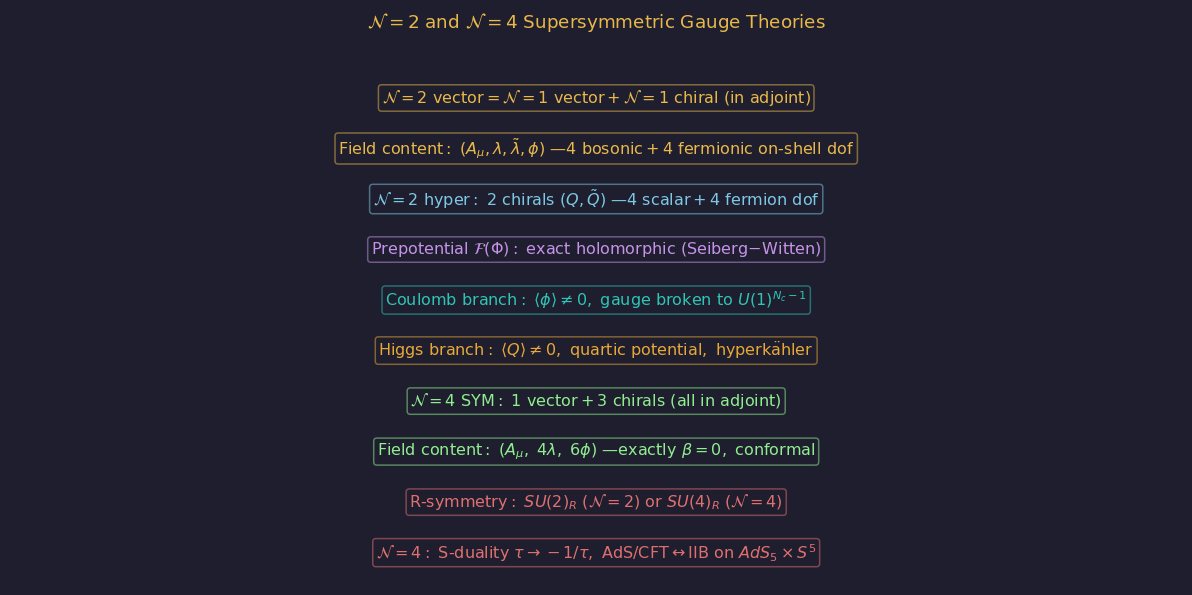

In [4]:

fig,ax=plt.subplots(figsize=(11,5.5))
fig.suptitle(r'$\mathcal{N}=2$ and $\mathcal{N}=4$ Supersymmetric Gauge Theories',color=GOLD,fontsize=12)
ax.set_facecolor(BG); ax.axis('off')
rows = [
    r'$\mathcal{N}=2\ \mathrm{vector} = \mathcal{N}=1\ \mathrm{vector} + \mathcal{N}=1\ \mathrm{chiral\ (in\ adjoint)}$',
    r'$\mathrm{Field\ content:}\ (A_\mu,\lambda,\tilde\lambda,\phi)\ \mathrm{— 4\ bosonic + 4\ fermionic\ on\text{-}shell\ dof}$',
    r'$\mathcal{N}=2\ \mathrm{hyper:\ 2\ chirals}\ (Q,\tilde Q)\ \mathrm{— 4\ scalar + 4\ fermion\ dof}$',
    r'$\mathrm{Prepotential}\ \mathcal{F}(\Phi)\mathrm{:\ exact\ holomorphic\ (Seiberg\!-\!Witten)}$',
    r'$\mathrm{Coulomb\ branch:}\ \langle\phi\rangle\neq 0,\ \mathrm{gauge\ broken\ to}\ U(1)^{N_c-1}$',
    r'$\mathrm{Higgs\ branch:}\ \langle Q\rangle\neq 0,\ \mathrm{quartic\ potential,\ hyperk\ddot{a}hler}$',
    r'$\mathcal{N}=4\ \mathrm{SYM:\ 1\ vector + 3\ chirals\ (all\ in\ adjoint)}$',
    r'$\mathrm{Field\ content:}\ (A_\mu,\ 4\lambda,\ 6\phi)\ \mathrm{— exactly}\ \beta=0,\ \mathrm{conformal}$',
    r'$\mathrm{R\text{-}symmetry:}\ SU(2)_R\ (\mathcal{N}=2)\ \mathrm{or}\ SU(4)_R\ (\mathcal{N}=4)$',
    r'$\mathcal{N}=4\mathrm{:\ S\text{-}duality}\ \tau\to -1/\tau,\ \mathrm{AdS/CFT} \leftrightarrow \mathrm{IIB\ on}\ AdS_5\times S^5$',
]
ys=np.linspace(0.93,0.06,len(rows))
colors=[GOLD,GOLD,BLUE,PURP,TEAL,ORAN,GREEN,GREEN,RED,RED]
for txt,y,col in zip(rows,ys,colors):
    ax.text(0.5,y,txt,ha='center',va='center',fontsize=10.5,color=col,
            transform=ax.transAxes,bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.5))
plt.tight_layout()
save('fig03_n2_n4.png',fig)


In [5]:

import shutil
shutil.make_archive('susyft_ch04_figures','zip','figures/ch04')
try:
    from google.colab import files; files.download('susyft_ch04_figures.zip')
except ImportError:
    print('figures saved to figures/ch04/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>